**Name:** Rahil  
**Roll No.:** 1024170352

### Setup
Install the libraries that may be missing (Colab already has most of them) and download the NLTK data used below.

In [1]:
!pip install -q nltk textblob wordcloud

In [2]:
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger_eng", "vader_lexicon"]:
    nltk.download(pkg, quiet=True)

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer

STOP_WORDS = set(stopwords.words("english"))
print("Setup done. Number of NLTK English stopwords:", len(STOP_WORDS))

Setup done. Number of NLTK English stopwords: 198


---
## Q1. Text preprocessing on my own paragraph
**Topic: Cricket.** A 6-sentence paragraph, then: lowercase + punctuation removal with `re`, word/sentence tokenization, `split()` vs `word_tokenize()`, stopword removal and a word-frequency distribution.

In [3]:
paragraph = (
    "Cricket isn't just a sport in India; it's a festival that brings whole neighbourhoods together! "
    "I started playing gully cricket with a taped tennis ball when I was 7, and the habit never left me. "
    "Watching a Test match teaches patience, while a T20 game packs pure adrenaline into three hours. "
    "My favourite memory is watching India win the 2011 World Cup final, when Dhoni finished the chase with a six. "
    "Players like Virat Kohli and Jasprit Bumrah show that fitness and discipline matter as much as talent. "
    "Even today, nothing beats a Sunday evening match with friends, followed by chai and endless arguments "
    "about who's the greatest batter."
)
print(paragraph)

Cricket isn't just a sport in India; it's a festival that brings whole neighbourhoods together! I started playing gully cricket with a taped tennis ball when I was 7, and the habit never left me. Watching a Test match teaches patience, while a T20 game packs pure adrenaline into three hours. My favourite memory is watching India win the 2011 World Cup final, when Dhoni finished the chase with a six. Players like Virat Kohli and Jasprit Bumrah show that fitness and discipline matter as much as talent. Even today, nothing beats a Sunday evening match with friends, followed by chai and endless arguments about who's the greatest batter.


**Q1.1 — Lowercase and remove punctuation using `re`.** The pattern `[^\w\s]` matches every character that is *not* a letter/digit/underscore and *not* whitespace, i.e. punctuation.

In [4]:
def clean_text(text):
    """Lowercase the text and strip punctuation with a regex."""
    text = text.lower()
    return re.sub(r"[^\w\s]", "", text)

clean_paragraph = clean_text(paragraph)
print(clean_paragraph)

cricket isnt just a sport in india its a festival that brings whole neighbourhoods together i started playing gully cricket with a taped tennis ball when i was 7 and the habit never left me watching a test match teaches patience while a t20 game packs pure adrenaline into three hours my favourite memory is watching india win the 2011 world cup final when dhoni finished the chase with a six players like virat kohli and jasprit bumrah show that fitness and discipline matter as much as talent even today nothing beats a sunday evening match with friends followed by chai and endless arguments about whos the greatest batter


**Q1.2 — Tokenize into sentences and words.** Sentence tokenization needs the full stops and `!`, so it is done on the *original* paragraph; word tokenization is done on the cleaned text.

In [5]:
def tokenize(original, cleaned):
    """Return (sentences from the original text, words from the cleaned text)."""
    return sent_tokenize(original), word_tokenize(cleaned)

sentences, words = tokenize(paragraph, clean_paragraph)
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences, 1):
    print(f"  {i}. {s}")
print("\nNumber of word tokens:", len(words))
print(words)

Number of sentences: 6
  1. Cricket isn't just a sport in India; it's a festival that brings whole neighbourhoods together!
  2. I started playing gully cricket with a taped tennis ball when I was 7, and the habit never left me.
  3. Watching a Test match teaches patience, while a T20 game packs pure adrenaline into three hours.
  4. My favourite memory is watching India win the 2011 World Cup final, when Dhoni finished the chase with a six.
  5. Players like Virat Kohli and Jasprit Bumrah show that fitness and discipline matter as much as talent.
  6. Even today, nothing beats a Sunday evening match with friends, followed by chai and endless arguments about who's the greatest batter.

Number of word tokens: 109
['cricket', 'isnt', 'just', 'a', 'sport', 'in', 'india', 'its', 'a', 'festival', 'that', 'brings', 'whole', 'neighbourhoods', 'together', 'i', 'started', 'playing', 'gully', 'cricket', 'with', 'a', 'taped', 'tennis', 'ball', 'when', 'i', 'was', '7', 'and', 'the', 'habit', 'neve

**Q1.3 — `split()` vs `word_tokenize()`** (both applied to the *raw* paragraph, so the difference is visible).

In [6]:
def compare_tokenizers(text):
    """Return the split() tokens, the word_tokenize() tokens and the tokens that differ."""
    split_tokens = text.split()
    nltk_tokens = word_tokenize(text)
    only_split = sorted(set(split_tokens) - set(nltk_tokens))
    only_nltk = sorted(set(nltk_tokens) - set(split_tokens))
    return split_tokens, nltk_tokens, only_split, only_nltk

split_tokens, nltk_tokens, only_split, only_nltk = compare_tokenizers(paragraph)
print("split()        ->", len(split_tokens), "tokens")
print("word_tokenize()->", len(nltk_tokens), "tokens\n")
print("Tokens produced only by split():\n", only_split)
print("\nTokens produced only by word_tokenize():\n", only_nltk)

split()        -> 109 tokens
word_tokenize()-> 124 tokens

Tokens produced only by split():
 ['7,', 'India;', 'batter.', 'final,', 'friends,', 'hours.', "isn't", "it's", 'me.', 'patience,', 'six.', 'talent.', 'today,', 'together!', "who's"]

Tokens produced only by word_tokenize():
 ['!', "'s", ',', '.', '7', ';', 'batter', 'final', 'friends', 'hours', 'it', 'me', "n't", 'patience', 'six', 'talent', 'today', 'together', 'who']


**Observation — how they differ:**

* `split()` only breaks on whitespace, so punctuation stays glued to words: `India;`, `together!`, `me.`, `7,`. To Python, `me.` and `me` are two different tokens.
* `word_tokenize()` (Penn Treebank rules) separates punctuation into its own tokens (`!`, `,`, `.`, `;`) and splits contractions into meaningful parts: `isn't → is + n't`, `it's → it + 's`, `who's → who + 's`.
* That is why `word_tokenize()` gives **124** tokens vs **109** for `split()`.
* **Conclusion:** `split()` is fine only for already-cleaned text; `word_tokenize()` is the right choice for raw text.

**Q1.4 — Remove stopwords** using NLTK's English stopword list.

In [7]:
def remove_stopwords(tokens):
    """Keep only tokens that are not in NLTK's English stopword list."""
    return [t for t in tokens if t not in STOP_WORDS]

filtered_words = remove_stopwords(words)
print("Before:", len(words), "tokens | After:", len(filtered_words), "tokens")
print(filtered_words)

Before: 109 tokens | After: 72 tokens
['cricket', 'isnt', 'sport', 'india', 'festival', 'brings', 'whole', 'neighbourhoods', 'together', 'started', 'playing', 'gully', 'cricket', 'taped', 'tennis', 'ball', '7', 'habit', 'never', 'left', 'watching', 'test', 'match', 'teaches', 'patience', 't20', 'game', 'packs', 'pure', 'adrenaline', 'three', 'hours', 'favourite', 'memory', 'watching', 'india', 'win', '2011', 'world', 'cup', 'final', 'dhoni', 'finished', 'chase', 'six', 'players', 'like', 'virat', 'kohli', 'jasprit', 'bumrah', 'show', 'fitness', 'discipline', 'matter', 'much', 'talent', 'even', 'today', 'nothing', 'beats', 'sunday', 'evening', 'match', 'friends', 'followed', 'chai', 'endless', 'arguments', 'whos', 'greatest', 'batter']


**Note:** 37 stopwords (a, in, the, and, with, …) were removed. `isnt` and `whos` survived because NLTK's list contains `isn't` and `isn` but not `isnt` — removing punctuation *before* stopword removal breaks contractions. In a real pipeline it is better to tokenize first (or expand contractions) and then remove stopwords.

**Q1.5 — Word frequency distribution (stopwords excluded).**

Distinct words: 68
Top 10: [('cricket', 2), ('india', 2), ('watching', 2), ('match', 2), ('isnt', 1), ('sport', 1), ('festival', 1), ('brings', 1), ('whole', 1), ('neighbourhoods', 1)]


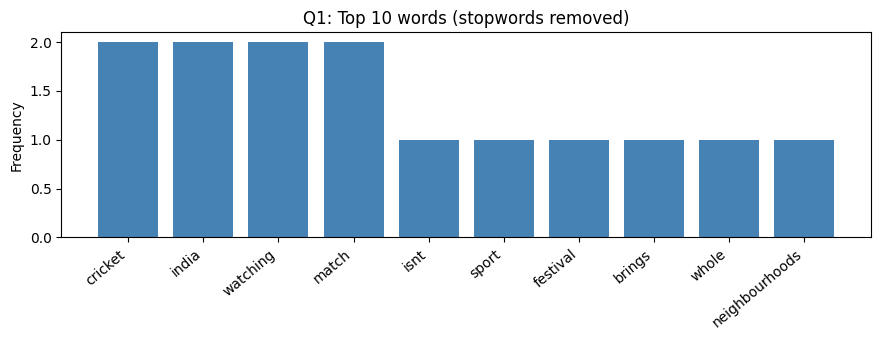

In [8]:
def word_frequency(tokens, top_n=10):
    """Return an NLTK FreqDist and its top_n most common words."""
    fdist = FreqDist(tokens)
    return fdist, fdist.most_common(top_n)

fdist, top_words = word_frequency(filtered_words)
print("Distinct words:", len(fdist))
print("Top 10:", top_words)

labels, counts = zip(*top_words)
plt.figure(figsize=(9, 3.5))
plt.bar(labels, counts, color="steelblue")
plt.title("Q1: Top 10 words (stopwords removed)")
plt.ylabel("Frequency")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

**Interpretation:** After removing stopwords the most frequent words are *cricket, india, watching* and *match* (2 times each) — exactly the theme of the paragraph. Every other word appears once, which is expected for a 6-sentence text.

---
## Q2. Regex extraction, stemming and lemmatization (same paragraph)

**Q2.1 — Extract alphabet-only words with `re.findall()`.** `\b[a-z]+\b` keeps a token only if it is made entirely of letters, so `7`, `2011` and `t20` are dropped.

In [9]:
def alpha_words(text):
    """Return all purely alphabetic words (lowercased) using re.findall."""
    return re.findall(r"\b[a-z]+\b", text.lower())

# Apply on the punctuation-free text so contractions stay whole ("isnt" instead of "isn" + "t")
alpha_tokens = alpha_words(clean_paragraph)
print(len(alpha_tokens), "alphabetic words")
print(alpha_tokens)

106 alphabetic words
['cricket', 'isnt', 'just', 'a', 'sport', 'in', 'india', 'its', 'a', 'festival', 'that', 'brings', 'whole', 'neighbourhoods', 'together', 'i', 'started', 'playing', 'gully', 'cricket', 'with', 'a', 'taped', 'tennis', 'ball', 'when', 'i', 'was', 'and', 'the', 'habit', 'never', 'left', 'me', 'watching', 'a', 'test', 'match', 'teaches', 'patience', 'while', 'a', 'game', 'packs', 'pure', 'adrenaline', 'into', 'three', 'hours', 'my', 'favourite', 'memory', 'is', 'watching', 'india', 'win', 'the', 'world', 'cup', 'final', 'when', 'dhoni', 'finished', 'the', 'chase', 'with', 'a', 'six', 'players', 'like', 'virat', 'kohli', 'and', 'jasprit', 'bumrah', 'show', 'that', 'fitness', 'and', 'discipline', 'matter', 'as', 'much', 'as', 'talent', 'even', 'today', 'nothing', 'beats', 'a', 'sunday', 'evening', 'match', 'with', 'friends', 'followed', 'by', 'chai', 'and', 'endless', 'arguments', 'about', 'whos', 'the', 'greatest', 'batter']


**Q2.2 — Remove stopwords.**

In [10]:
content_words = remove_stopwords(alpha_tokens)
print(len(content_words), "words after stopword removal")
print(content_words)

69 words after stopword removal
['cricket', 'isnt', 'sport', 'india', 'festival', 'brings', 'whole', 'neighbourhoods', 'together', 'started', 'playing', 'gully', 'cricket', 'taped', 'tennis', 'ball', 'habit', 'never', 'left', 'watching', 'test', 'match', 'teaches', 'patience', 'game', 'packs', 'pure', 'adrenaline', 'three', 'hours', 'favourite', 'memory', 'watching', 'india', 'win', 'world', 'cup', 'final', 'dhoni', 'finished', 'chase', 'six', 'players', 'like', 'virat', 'kohli', 'jasprit', 'bumrah', 'show', 'fitness', 'discipline', 'matter', 'much', 'talent', 'even', 'today', 'nothing', 'beats', 'sunday', 'evening', 'match', 'friends', 'followed', 'chai', 'endless', 'arguments', 'whos', 'greatest', 'batter']


**Q2.3 — Stemming with `PorterStemmer`.** Stemming chops suffixes using fixed rules; the output does not have to be a real word.

In [11]:
stemmer = PorterStemmer()

def stem_words(tokens):
    """Return the Porter stem of every token."""
    return [stemmer.stem(t) for t in tokens]

stemmed = stem_words(content_words)
print(stemmed)

['cricket', 'isnt', 'sport', 'india', 'festiv', 'bring', 'whole', 'neighbourhood', 'togeth', 'start', 'play', 'gulli', 'cricket', 'tape', 'tenni', 'ball', 'habit', 'never', 'left', 'watch', 'test', 'match', 'teach', 'patienc', 'game', 'pack', 'pure', 'adrenalin', 'three', 'hour', 'favourit', 'memori', 'watch', 'india', 'win', 'world', 'cup', 'final', 'dhoni', 'finish', 'chase', 'six', 'player', 'like', 'virat', 'kohli', 'jasprit', 'bumrah', 'show', 'fit', 'disciplin', 'matter', 'much', 'talent', 'even', 'today', 'noth', 'beat', 'sunday', 'even', 'match', 'friend', 'follow', 'chai', 'endless', 'argument', 'who', 'greatest', 'batter']


**Q2.4 — Lemmatization with `WordNetLemmatizer`.** By default the lemmatizer treats every word as a noun, so verbs like *watching* are not reduced. I therefore pass the part-of-speech tag from `nltk.pos_tag` as well, and show both versions.

In [12]:
lemmatizer = WordNetLemmatizer()

def to_wordnet_pos(treebank_tag):
    """Map a Penn Treebank POS tag to the WordNet POS constant."""
    if treebank_tag.startswith("J"):
        return wordnet.ADJ
    if treebank_tag.startswith("V"):
        return wordnet.VERB
    if treebank_tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

def lemmatize_words(tokens, use_pos=True):
    """Return WordNet lemmas, optionally using POS tags for better results."""
    if not use_pos:
        return [lemmatizer.lemmatize(t) for t in tokens]
    tagged = nltk.pos_tag(tokens)
    return [lemmatizer.lemmatize(word, to_wordnet_pos(tag)) for word, tag in tagged]

lemmas_default = lemmatize_words(content_words, use_pos=False)
lemmas_pos = lemmatize_words(content_words, use_pos=True)
print("Default (noun) lemmas:\n", lemmas_default)
print("\nPOS-aware lemmas:\n", lemmas_pos)

Default (noun) lemmas:
 ['cricket', 'isnt', 'sport', 'india', 'festival', 'brings', 'whole', 'neighbourhood', 'together', 'started', 'playing', 'gully', 'cricket', 'taped', 'tennis', 'ball', 'habit', 'never', 'left', 'watching', 'test', 'match', 'teach', 'patience', 'game', 'pack', 'pure', 'adrenaline', 'three', 'hour', 'favourite', 'memory', 'watching', 'india', 'win', 'world', 'cup', 'final', 'dhoni', 'finished', 'chase', 'six', 'player', 'like', 'virat', 'kohli', 'jasprit', 'bumrah', 'show', 'fitness', 'discipline', 'matter', 'much', 'talent', 'even', 'today', 'nothing', 'beat', 'sunday', 'evening', 'match', 'friend', 'followed', 'chai', 'endless', 'argument', 'who', 'greatest', 'batter']

POS-aware lemmas:
 ['cricket', 'isnt', 'sport', 'india', 'festival', 'brings', 'whole', 'neighbourhood', 'together', 'start', 'play', 'gully', 'cricket', 'tap', 'tennis', 'ball', 'habit', 'never', 'leave', 'watch', 'test', 'match', 'teach', 'patience', 'game', 'pack', 'pure', 'adrenaline', 'three'

**Q2.5 — Compare stemmed and lemmatized outputs.** The table lists only the words where at least one method changed the word.

In [13]:
def compare_stem_lemma(tokens, stems, lemmas):
    """Return a DataFrame of words that were changed by stemming or lemmatization."""
    df = pd.DataFrame({"word": tokens, "porter_stem": stems, "wordnet_lemma": lemmas})
    df = df.drop_duplicates()
    changed = df[(df.word != df.porter_stem) | (df.word != df.wordnet_lemma)]
    return changed.reset_index(drop=True)

comparison = compare_stem_lemma(content_words, stemmed, lemmas_pos)
comparison

,word,porter_stem,wordnet_lemma
0,festival,festiv,festival
1,brings,bring,brings
2,neighbourhoods,neighbourhood,neighbourhood
3,together,togeth,together
4,started,start,start
5,playing,play,play
6,gully,gulli,gully
7,taped,tape,tap
8,tennis,tenni,tennis
9,left,left,leave


**Comparison:**

| Aspect | Stemming (Porter) | Lemmatization (WordNet) |
|---|---|---|
| Method | Cuts suffixes with fixed rules | Looks the word up in a dictionary (uses POS) |
| Output | Often not a real word: `festiv`, `togeth`, `patienc`, `memori`, `noth` | Real dictionary words: `festival`, `together`, `patience`, `memory` |
| Verbs | `watching → watch`, `started → start` | Same, **and** irregular forms: `left → leave` |
| Mistakes seen here | `evening → even` (now collides with the word *even*), `fitness → fit` (meaning changed) | `taped → tap` (picked the wrong verb), `brings` not reduced because the POS tagger called it a noun |
| Speed | Very fast, no dictionary | Slower, needs WordNet + POS tagging |

**When I would use which:**
* **Stemming** — when speed and recall matter more than readability: search engines, indexing, bag-of-words models on large corpora, where `watch/watching/watches` just need to fall in the same bucket.
* **Lemmatization** — when the output must be real words or meaning matters: chatbots, question answering, text shown to users, or features for a model where `evening` and `even` must stay different.
* Lemmatization only works well with the correct POS tag — without it (the *default* version above) `started`, `playing`, `watching` were left unchanged.

---
## Q3. Bag of Words and TF-IDF on 3 texts of my own
Three short product reviews. Each review repeats its main subject on purpose, so TF-IDF has something to pick out. English stopwords are removed (`stop_words="english"`) so words like *the* and *is* do not fill the vocabulary.

In [14]:
reviews_q3 = [
    "The phone camera is brilliant and the camera works well even at night. Battery life is decent.",
    "This laptop is fast, but the battery drains quickly and the battery charger heats up. The keyboard feels cheap.",
    "These headphones have deep bass and the noise cancellation is brilliant. Bass lovers will enjoy them.",
]
names_q3 = ["Text 1 (phone)", "Text 2 (laptop)", "Text 3 (headphones)"]
for n, t in zip(names_q3, reviews_q3):
    print(f"{n}: {t}")

Text 1 (phone): The phone camera is brilliant and the camera works well even at night. Battery life is decent.
Text 2 (laptop): This laptop is fast, but the battery drains quickly and the battery charger heats up. The keyboard feels cheap.
Text 3 (headphones): These headphones have deep bass and the noise cancellation is brilliant. Bass lovers will enjoy them.


**Q3.1 — Bag of Words with `CountVectorizer`.** Each row is a text, each column a word, each cell a raw count.

In [15]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

def bag_of_words(docs):
    """Return the BoW count matrix as a labelled DataFrame."""
    cv = CountVectorizer(stop_words="english")
    matrix = cv.fit_transform(docs)
    return pd.DataFrame(matrix.toarray(), index=names_q3, columns=cv.get_feature_names_out())

bow_df = bag_of_words(reviews_q3)
print("Vocabulary size:", bow_df.shape[1])
bow_df

Vocabulary size: 24


,bass,battery,brilliant,camera,cancellation,charger,cheap,decent,deep,drains,...,heats,keyboard,laptop,life,lovers,night,noise,phone,quickly,works
Text 1 (phone),0,1,1,2,0,0,0,1,0,0,...,0,0,0,1,0,1,0,1,0,1
Text 2 (laptop),0,2,0,0,0,1,1,0,0,1,...,1,1,1,0,0,0,0,0,1,0
Text 3 (headphones),2,0,1,0,1,0,0,0,1,0,...,0,0,0,0,1,0,1,0,0,0


**Q3.2 — TF-IDF scores with `TfidfVectorizer`.** A word's weight rises with how often it appears in *this* text and falls if it also appears in other texts (sklearn uses smoothed IDF and L2-normalises each row).

In [16]:
def tfidf_scores(docs):
    """Return the TF-IDF matrix as a labelled DataFrame."""
    tv = TfidfVectorizer(stop_words="english")
    matrix = tv.fit_transform(docs)
    return pd.DataFrame(matrix.toarray(), index=names_q3, columns=tv.get_feature_names_out())

tfidf_df = tfidf_scores(reviews_q3)
tfidf_df.round(3)

,bass,battery,brilliant,camera,cancellation,charger,cheap,decent,deep,drains,...,heats,keyboard,laptop,life,lovers,night,noise,phone,quickly,works
Text 1 (phone),0.000,0.239,0.239,0.628,0.000,0.000,0.000,0.314,0.000,0.000,...,0.000,0.000,0.000,0.314,0.000,0.314,0.000,0.314,0.000,0.314
Text 2 (laptop),0.000,0.452,0.000,0.000,0.000,0.297,0.297,0.000,0.000,0.297,...,0.297,0.297,0.297,0.000,0.000,0.000,0.000,0.000,0.297,0.000
Text 3 (headphones),0.615,0.000,0.234,0.000,0.307,0.000,0.000,0.000,0.307,0.000,...,0.000,0.000,0.000,0.000,0.307,0.000,0.307,0.000,0.000,0.000


**Q3.3 — Top 3 keywords per text.** Ties are broken alphabetically so the output is reproducible.

In [17]:
def top_keywords(tfidf_frame, k=3):
    """Return {text name: [(word, score), ...]} with the k highest TF-IDF words."""
    result = {}
    for name, row in tfidf_frame.iterrows():
        row = row[row > 0]
        ranked = sorted(row.items(), key=lambda kv: (-kv[1], kv[0]))[:k]
        result[name] = [(w, round(s, 3)) for w, s in ranked]
    return result

for name, kws in top_keywords(tfidf_df).items():
    print(f"{name}: {kws}")

Text 1 (phone): [('camera', 0.628), ('decent', 0.314), ('life', 0.314)]
Text 2 (laptop): [('battery', 0.452), ('charger', 0.297), ('cheap', 0.297)]
Text 3 (headphones): [('bass', 0.615), ('cancellation', 0.307), ('deep', 0.307)]


**Interpretation:**

* **Text 1 (phone): `camera` (0.628)** clearly dominates — it appears twice and in no other text, so both TF and IDF are high. `battery` and `brilliant` also appear twice in the collection, so they are *penalised* (0.239) even though they are in this text. `decent` and `life` are tied with `night`, `phone`, `works` (0.314 each, all used once and unique to this text); the tie is broken alphabetically.
* **Text 2 (laptop): `battery` (0.452)** wins because it is repeated twice. It also appears in Text 1, so its IDF is lower, but the double count still lifts it above the single-use words. `charger` and `cheap` (0.297) come next — they describe the complaint.
* **Text 3 (headphones): `bass` (0.615)** — repeated and unique, so it is the strongest keyword; `cancellation` and `deep` (0.307) follow.
* **Takeaway:** TF-IDF correctly found the *subject* of each review (camera, battery, bass) and ignored words shared across reviews (`brilliant`). With very short texts most words appear only once, so many words tie — TF-IDF becomes more informative as documents get longer.

---
## Q4. Jaccard vs Cosine similarity for two technologies
**Cloud Computing** vs **Internet of Things (IoT)** — two different technologies that still share some vocabulary (data, devices, internet), which makes the comparison interesting.

In [18]:
tech_cloud = (
    "Cloud computing delivers servers, storage and software over the internet. "
    "Companies rent computing power instead of buying their own hardware. "
    "Data is stored in large data centres and can be accessed from any device. "
    "Users pay only for the resources they use, and the service scales up or down on demand. "
    "Popular cloud services include online storage, web hosting and machine learning platforms."
)
tech_iot = (
    "The Internet of Things connects everyday devices such as fans, watches and cars to the internet. "
    "Sensors in these devices collect data about temperature, motion and location. "
    "The devices send this data to apps so people can monitor and control them remotely. "
    "Smart homes, fitness bands and smart farming are common examples of IoT. "
    "Because so many devices are connected, security and battery life are major challenges."
)
print("Text A (Cloud):", tech_cloud)
print("\nText B (IoT):", tech_iot)

Text A (Cloud): Cloud computing delivers servers, storage and software over the internet. Companies rent computing power instead of buying their own hardware. Data is stored in large data centres and can be accessed from any device. Users pay only for the resources they use, and the service scales up or down on demand. Popular cloud services include online storage, web hosting and machine learning platforms.

Text B (IoT): The Internet of Things connects everyday devices such as fans, watches and cars to the internet. Sensors in these devices collect data about temperature, motion and location. The devices send this data to apps so people can monitor and control them remotely. Smart homes, fitness bands and smart farming are common examples of IoT. Because so many devices are connected, security and battery life are major challenges.


**Q4.1 — Preprocess and tokenize both texts:** lowercase → remove punctuation → tokenize → drop stopwords and non-alphabetic tokens → POS-aware lemmatization (so *devices* and *device* count as the same word).

In [19]:
def preprocess(text):
    """Full pipeline: clean, tokenize, remove stopwords, lemmatize. Returns a token list."""
    tokens = word_tokenize(clean_text(text))
    tokens = [t for t in tokens if t.isalpha() and t not in STOP_WORDS]
    return lemmatize_words(tokens, use_pos=True)

tokens_cloud = preprocess(tech_cloud)
tokens_iot = preprocess(tech_iot)
print("Cloud tokens:", tokens_cloud)
print("\nIoT tokens:  ", tokens_iot)

Cloud tokens: ['cloud', 'compute', 'delivers', 'server', 'storage', 'software', 'internet', 'company', 'rent', 'compute', 'power', 'instead', 'buy', 'hardware', 'data', 'store', 'large', 'data', 'centre', 'access', 'device', 'user', 'pay', 'resource', 'use', 'service', 'scale', 'demand', 'popular', 'cloud', 'service', 'include', 'online', 'storage', 'web', 'host', 'machine', 'learning', 'platform']

IoT tokens:   ['internet', 'thing', 'connects', 'everyday', 'device', 'fan', 'watch', 'car', 'internet', 'sensor', 'device', 'collect', 'data', 'temperature', 'motion', 'location', 'device', 'send', 'data', 'apps', 'people', 'monitor', 'control', 'remotely', 'smart', 'home', 'fitness', 'band', 'smart', 'farm', 'common', 'example', 'iot', 'many', 'device', 'connect', 'security', 'battery', 'life', 'major', 'challenge']


**Q4.2(a) — Jaccard similarity using sets:** |A ∩ B| / |A ∪ B|.

In [20]:
def jaccard_similarity(tokens_a, tokens_b):
    """Return (Jaccard score, shared words) using Python sets."""
    a, b = set(tokens_a), set(tokens_b)
    shared = a & b
    return len(shared) / len(a | b), shared

jaccard, shared_words = jaccard_similarity(tokens_cloud, tokens_iot)
print("Unique words  -> Cloud:", len(set(tokens_cloud)), "| IoT:", len(set(tokens_iot)))
print("Shared words  ->", sorted(shared_words))
print("Union size    ->", len(set(tokens_cloud) | set(tokens_iot)))
print("Jaccard similarity:", round(jaccard, 3))

Unique words  -> Cloud: 34 | IoT: 35
Shared words  -> ['data', 'device', 'internet']
Union size    -> 66
Jaccard similarity: 0.045


**Q4.2(b) — Cosine similarity using `TfidfVectorizer` + `cosine_similarity()`** on the preprocessed texts.

In [21]:
from sklearn.metrics.pairwise import cosine_similarity

def tfidf_cosine(tokens_a, tokens_b):
    """Return the cosine similarity of the TF-IDF vectors of two token lists."""
    docs = [" ".join(tokens_a), " ".join(tokens_b)]
    tv = TfidfVectorizer()
    vectors = tv.fit_transform(docs)
    return float(cosine_similarity(vectors[0:1], vectors[1:2])[0, 0]), tv, vectors

cosine, tv_q4, vec_q4 = tfidf_cosine(tokens_cloud, tokens_iot)
print("Cosine similarity (TF-IDF):", round(cosine, 3))

# Show the weights of the shared words in each vector
weights = pd.DataFrame(vec_q4.toarray(), index=["Cloud", "IoT"], columns=tv_q4.get_feature_names_out())
weights[sorted(shared_words)].round(3)

Cosine similarity (TF-IDF): 0.109


,data,device,internet
Cloud,0.210,0.105,0.105
IoT,0.207,0.414,0.207


**Q4.2(c) — Which metric gives better insight here?**

**Results:** Jaccard = **0.045**, Cosine (TF-IDF) = **0.109**.

* **Jaccard** only checks *whether* a word is present. 3 shared words (`data`, `device`, `internet`) out of 66 unique words gives a very low score. It ignores that `device` appears **4 times** in the IoT text and `data` twice in both — repetition is thrown away when we convert to a set.
* **Cosine with TF-IDF** uses word *frequencies* and weights. The shared words `data` and `device` carry high weight in the IoT vector (0.207 and 0.414), so the overlap counts for more and the score is more than double Jaccard's. Cosine is also independent of document length, because it compares the *direction* of the vectors.
* **Which gives better insight here?** Cosine similarity. Both technologies really are related (cloud platforms store and process the data that IoT devices produce), and cosine reflects that the shared words are *central* to both texts, while Jaccard treats every word as equally important and says the texts are almost unrelated.
* Jaccard is still useful as a quick, easy-to-explain measure for short texts or keyword sets (e.g. tags, duplicate detection), but it cannot capture importance or frequency.
* Both scores are low overall because the two texts use mostly different vocabulary and these methods don't understand synonyms; word embeddings would be needed to capture meaning-level similarity.

---
## Q5. Sentiment analysis of reviews
Short reviews of a **food delivery app**. The first one is my own review; the rest are written to cover positive, negative and neutral cases.

* **TextBlob** gives *polarity* (−1 negative … +1 positive) and *subjectivity* (0 factual … 1 opinion).
* **VADER** compound score is shown as a cross-check (it is tuned for short, informal text).
* **Classification rule (TextBlob polarity):** > 0.05 → Positive, < −0.05 → Negative, otherwise Neutral.

In [22]:
from textblob import TextBlob
from nltk.sentiment import SentimentIntensityAnalyzer

reviews_q5 = [
    "I love this app! The food arrived hot and fresh, and the delivery was super fast.",
    "Great discounts on weekends and the tracking feature is really accurate.",
    "The rider was very polite and the packaging was neat. Excellent service overall.",
    "Terrible experience. My order came an hour late and the pizza was cold.",
    "The app keeps crashing during payment, which is really annoying.",
    "I ordered a paneer wrap at 8 pm and it was delivered at 8:40 pm.",
]

vader = SentimentIntensityAnalyzer()

def classify(polarity, threshold=0.05):
    """Map a polarity score to Positive / Negative / Neutral."""
    if polarity > threshold:
        return "Positive"
    if polarity < -threshold:
        return "Negative"
    return "Neutral"

def analyse_reviews(reviews):
    """Return a DataFrame with TextBlob polarity/subjectivity, VADER compound and the label."""
    rows = []
    for r in reviews:
        s = TextBlob(r).sentiment
        rows.append({
            "review": r,
            "polarity": round(s.polarity, 3),
            "subjectivity": round(s.subjectivity, 3),
            "vader_compound": round(vader.polarity_scores(r)["compound"], 3),
            "sentiment": classify(s.polarity),
        })
    return pd.DataFrame(rows)

pd.set_option("display.max_colwidth", None)
sentiment_df = analyse_reviews(reviews_q5)
sentiment_df

,review,polarity,subjectivity,vader_compound,sentiment
0,"I love this app! The food arrived hot and fresh, and the delivery was super fast.",0.342,0.643,0.893,Positive
1,Great discounts on weekends and the tracking feature is really accurate.,0.600,0.692,0.625,Positive
2,The rider was very polite and the packaging was neat. Excellent service overall.,0.400,0.433,0.772,Positive
3,Terrible experience. My order came an hour late and the pizza was cold.,-0.633,0.867,-0.477,Negative
4,"The app keeps crashing during payment, which is really annoying.",-0.800,0.900,-0.458,Negative
5,I ordered a paneer wrap at 8 pm and it was delivered at 8:40 pm.,0.000,0.000,0.000,Neutral


In [23]:
print(sentiment_df["sentiment"].value_counts())

sentiment
Positive    3
Negative    2
Neutral     1
Name: count, dtype: int64


**Interpretation:**

* **Positive (3):** words like *love, great, excellent, polite, fresh* push polarity above 0.3. Review 2 has the highest polarity (0.600) because *great* and *accurate* are both strongly positive.
* **Negative (2):** *terrible, late, cold* and *annoying, crashing*. Review 5 is the most negative (−0.800) and also the most subjective (0.900) — it is a pure opinion.
* **Neutral (1):** the paneer-wrap review only states facts (order time and delivery time), so both polarity **and** subjectivity are 0.0 — a good example that *neutral* usually means *objective*.
* **Subjectivity:** all opinion reviews score 0.43–0.90; review 3 is the least subjective of the positives (0.433) because *neat* and *overall* are milder words.
* VADER agrees with TextBlob on all six labels. VADER gives the positive reviews higher scores (e.g. 0.893 for review 1) because it accounts for the exclamation mark and intensifiers like *super*.

**Q5.3 — Word cloud of all positive reviews** (stopwords removed so the cloud shows meaningful words).

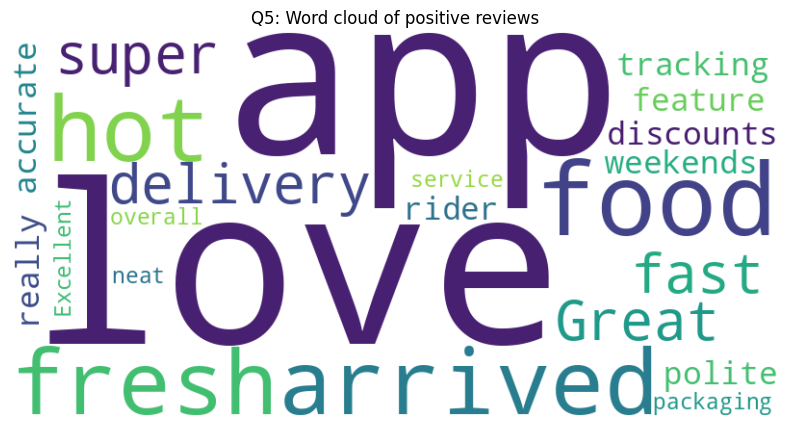

In [24]:
from wordcloud import WordCloud

def positive_wordcloud(df):
    """Build and return a WordCloud from every review labelled Positive."""
    positive_text = " ".join(df.loc[df["sentiment"] == "Positive", "review"])
    return WordCloud(width=800, height=400, background_color="white",
                     stopwords=STOP_WORDS, colormap="viridis",
                     random_state=42).generate(positive_text)

wc = positive_wordcloud(sentiment_df)
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Q5: Word cloud of positive reviews")
plt.show()

---
## Q6. Text generation with an LSTM
Training data: my own ~100-word paragraph. Steps: `Tokenizer()` → n-gram input sequences → padding → Embedding + LSTM + Dense(softmax) → train → generate new lines from seed words.

*Note:* input sequences are built **sentence by sentence** (not across the whole paragraph), so the model learns word order inside a sentence and the sequences stay short.

In [25]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

tf.keras.utils.set_random_seed(42)   # reproducible weights and sampling

training_paragraph = (
    "The night before an exam is always the longest night of the semester. "
    "I open my notes and promise myself that I will study every chapter. "
    "Then I check my phone for one minute and the minute becomes an hour. "
    "My friends send memes about the exam and we laugh about the syllabus. "
    "At midnight I make strong tea and finally start to study the notes. "
    "The chapters slowly make sense and the formulas stop looking scary. "
    "By morning I am tired but confident, and I promise myself that next semester "
    "I will study every day and not only the night before the exam."
)
print(len(training_paragraph.split()), "words in the training paragraph")

104 words in the training paragraph


**Q6.1 — Tokenize with `Tokenizer()`.** Each unique word gets an integer id (most frequent word = 1).

In [26]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_paragraph])
vocab_size = len(tokenizer.word_index) + 1   # +1 because id 0 is reserved for padding
print("Vocabulary size:", vocab_size)
print("First 15 entries of word_index:", dict(list(tokenizer.word_index.items())[:15]))

Vocabulary size: 63
First 15 entries of word_index: {'the': 1, 'i': 2, 'and': 3, 'night': 4, 'exam': 5, 'my': 6, 'study': 7, 'before': 8, 'an': 9, 'semester': 10, 'notes': 11, 'promise': 12, 'myself': 13, 'that': 14, 'will': 15}


**Q6.2 — Create input sequences and build the model.** For the sentence *"i open my notes"* the n-gram sequences are `[i, open]`, `[i, open, my]`, `[i, open, my, notes]`; the last word of each sequence is the label (y) and the words before it are the input (X).

In [27]:
def make_sequences(text, tok):
    """Return padded n-gram sequences (one set per sentence) and the max length."""
    sequences = []
    for sentence in sent_tokenize(text):
        ids = tok.texts_to_sequences([sentence])[0]
        for i in range(2, len(ids) + 1):
            sequences.append(ids[:i])
    max_len = max(len(s) for s in sequences)
    return np.array(pad_sequences(sequences, maxlen=max_len, padding="pre")), max_len

padded, max_len = make_sequences(training_paragraph, tokenizer)
X, y_ids = padded[:, :-1], padded[:, -1]
y = tf.keras.utils.to_categorical(y_ids, num_classes=vocab_size)

print("Number of training sequences:", len(padded))
print("Longest sequence length:", max_len)
print("X shape:", X.shape, "| y shape:", y.shape)
print("Example padded sequences:\n", padded[:4])

Number of training sequences: 97
Longest sequence length: 27
X shape: (97, 26) | y shape: (97, 63)
Example padded sequences:
 [[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 4]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 4 8]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 4 8 9]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 4 8 9 5]]


In [28]:
def build_model(vocab, input_len):
    """Embedding -> LSTM -> Dense(softmax) next-word predictor."""
    m = Sequential([
        Input(shape=(input_len,)),
        Embedding(vocab, 32),          # learns a 32-dim vector per word
        LSTM(100),                     # learns the order of words
        Dense(vocab, activation="softmax"),  # probability of each next word
    ])
    m.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return m

model = build_model(vocab_size, X.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 26, 32)         │         2,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100)            │        53,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 63)             │         6,363 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,579 (240.54 KB)

 Trainable params: 61,579 (240.54 KB)

 Non-trainable params: 0 (0.00 B)

**Q6.3 — Train the model and generate new lines.**

Final training loss: 0.176
Final training accuracy: 0.979


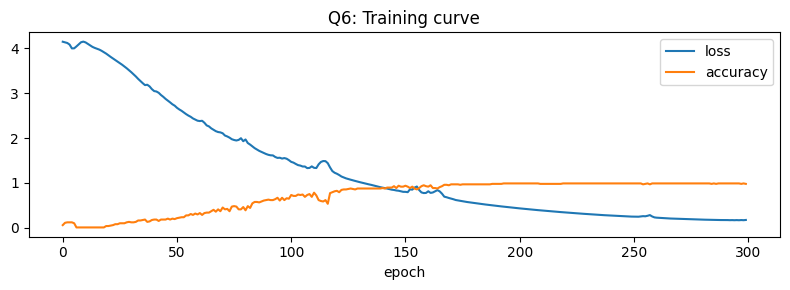

In [29]:
history = model.fit(X, y, epochs=300, verbose=0)
print(f"Final training loss: {history.history['loss'][-1]:.3f}")
print(f"Final training accuracy: {history.history['accuracy'][-1]:.3f}")

plt.figure(figsize=(8, 3))
plt.plot(history.history["loss"], label="loss")
plt.plot(history.history["accuracy"], label="accuracy")
plt.xlabel("epoch")
plt.title("Q6: Training curve")
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
def generate_line(seed, n_words=10, temperature=0.8):
    """Generate n_words after the seed by repeatedly predicting the next word.
    temperature < 1 keeps choices close to the most likely word; temperature = 0 means always argmax."""
    text = seed
    for _ in range(n_words):
        ids = tokenizer.texts_to_sequences([text])[0]
        ids = pad_sequences([ids], maxlen=X.shape[1], padding="pre")
        probs = model.predict(ids, verbose=0)[0]
        probs[0] = 0                                  # never predict padding
        if temperature == 0:
            next_id = int(np.argmax(probs))
        else:
            logits = np.log(probs + 1e-9) / temperature
            p = np.exp(logits) / np.sum(np.exp(logits))
            next_id = int(np.random.choice(len(p), p=p))
        text += " " + tokenizer.index_word[next_id]
    return text

seeds = ["exam", "my friends", "tea"]
print("Generated lines:\n")
for seed in seeds:
    print("  •", generate_line(seed, n_words=10))

Generated lines:



  • exam friends morning i am tired tired and confident and myself


  • my friends about memes about the exam and we laugh about the


  • tea midnight i make strong tea and finally start to study


**Observations:**

* The model reaches high training accuracy (about 98%) after 300 epochs, but this is **memorisation**, not understanding — with only ~100 words there is no validation data to check generalisation.
* The generated lines are grammatical in parts because they reuse phrases from the paragraph (e.g. *"i make strong tea and finally start to study"*). When the seed starts a new context the model jumps between sentences it has seen, which is what produces the mixed lines.
* `temperature` controls randomness: `temperature=0` always picks the most likely word (repeats the training text exactly or gets stuck in loops, like the demo cell's *"machine learning learning learning"*), while higher values give more variety but less sense.
* The exact generated lines may differ slightly when the notebook is re-run on a different machine (e.g. Colab GPU) even with the fixed seed.
* To get genuinely new text we would need a much larger corpus, a validation split, and possibly dropout or a character-level model.

---
## Reference: lab demo code (original cells from the notebook)

In [31]:
# ============================================================
# NLP LAB-II: TEXT FEATURES, SIMILARITY, SENTIMENT AND GENERATION
# Each section demonstrates one PPT concept with short comments.
# ============================================================

# Computers understand numbers more easily than human language.
# So, before using machine learning on text, we need to convert the text into numbers.
# Bag of Words counts how many times each word appears in a document.

print("\n--- 1. Bag of Words ---")
# Bag of Words (BoW) converts documents into word counts.
# Each row is a document; each column is a word.
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "I love machine learning",
    "Machine learning is amazing",
    "I love coding"
]
vectorizer = CountVectorizer()
bow = vectorizer.fit_transform(texts)
print("Vocabulary:", vectorizer.get_feature_names_out())
print("BoW matrix:\n", bow.toarray())


--- 1. Bag of Words ---
Vocabulary: ['amazing' 'coding' 'is' 'learning' 'love' 'machine']
BoW matrix:
 [[0 0 0 1 1 1]
 [1 0 1 1 0 1]
 [0 1 0 0 1 0]]


In [32]:
print("\n--- 2. BoW with bigrams ---")

# A unigram is one word, a bigram is a pair of consecutive words, and a trigram is a group of three consecutive words.

# ngram_range=(2, 2) includes pairs of consecutive words.
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
bigram_matrix = bigram_vectorizer.fit_transform(texts)
print("Bigram vocabulary:", bigram_vectorizer.get_feature_names_out())
print("Bigram matrix:\n", bigram_matrix.toarray())


--- 2. BoW with bigrams ---
Bigram vocabulary: ['is amazing' 'learning is' 'love coding' 'love machine'
 'machine learning']
Bigram matrix:
 [[0 0 0 1 1]
 [1 1 0 0 1]
 [0 0 1 0 0]]


In [33]:
print("\n--- 3. BoW with unigrams and bigrams ---")
# ngram_range=(1, 2) includes single words and two-word combinations.
uni_bi_vectorizer = CountVectorizer(ngram_range=(1, 2))
uni_bi_matrix = uni_bi_vectorizer.fit_transform(texts)
print("Unigrams + bigrams:", uni_bi_vectorizer.get_feature_names_out())
print("Matrix shape:", uni_bi_matrix.shape)


--- 3. BoW with unigrams and bigrams ---
Unigrams + bigrams: ['amazing' 'coding' 'is' 'is amazing' 'learning' 'learning is' 'love'
 'love coding' 'love machine' 'machine' 'machine learning']
Matrix shape: (3, 11)


In [34]:
print("\n--- 4. TF-IDF ---")
# Term Frequency-Inverse Document Frequency

# Bag of Words counts words, but a very common word may not tell us much about a document.
# TF-IDF gives a weight to a word based on how often it occurs in a document and how common it is across the collection.

# TF-IDF weights words based on their frequency and usefulness
# across the collection of documents.
tfidf_vectorizer = TfidfVectorizer()
tfidf = tfidf_vectorizer.fit_transform(texts)
print("Vocabulary:", tfidf_vectorizer.get_feature_names_out())
print("TF-IDF matrix:\n", tfidf.toarray().round(3))


--- 4. TF-IDF ---
Vocabulary: ['amazing' 'coding' 'is' 'learning' 'love' 'machine']
TF-IDF matrix:
 [[0.    0.    0.    0.577 0.577 0.577]
 [0.563 0.    0.563 0.428 0.    0.428]
 [0.    0.796 0.    0.    0.605 0.   ]]


In [35]:
print("\n--- 5. Jaccard similarity ---")

# Suppose two students write sentences about the same topic.
# How can we estimate how many words they have in common?
# Jaccard similarity compares the unique words in both sentences.
# Jaccard = shared unique words / all unique words in either text.
text1 = "machine learning is fun"
text2 = "learning about machine intelligence"

set1 = set(text1.split())
set2 = set(text2.split())

jaccard = len(set1 & set2) / len(set1 | set2)
print("Common words:", set1 & set2)
print("Jaccard similarity:", round(jaccard, 3))


--- 5. Jaccard similarity ---
Common words: {'learning', 'machine'}
Jaccard similarity: 0.333


In [36]:
print("\n--- 6. Cosine similarity ---")

# Cosine similarity is another way to compare documents.
# Instead of directly comparing sets of words, we convert the documents into numerical vectors and compare the direction of those vectors.

# Cosine similarity compares numerical vectors.
# Here, TF-IDF converts text into vectors.
from sklearn.metrics.pairwise import cosine_similarity

tfidf_pair = TfidfVectorizer()
vectors = tfidf_pair.fit_transform([text1, text2])
cosine_score = cosine_similarity(vectors[0:1], vectors[1:2])[0, 0]

print("Cosine similarity:", round(float(cosine_score), 3))
print("Jaccard uses word sets; cosine uses numerical vectors.")


--- 6. Cosine similarity ---
Cosine similarity: 0.336
Jaccard uses word sets; cosine uses numerical vectors.


In [37]:
print("\n--- 7. Sentiment analysis with TextBlob ---")

# Sentiment analysis tries to identify the opinion or emotion expressed in text.
# For example, we may want to know whether a customer review is positive, negative, or neutral.

# Polarity ranges from -1 (negative) to +1 (positive).
# Subjectivity ranges from 0 (objective) to 1 (subjective).

# Polarity: Estimates whether the text is negative or positive.
# Subjectivity: Estimates whether the text is more factual or opinion-based.

try:
    from textblob import TextBlob

    review = "The service was excellent and the staff was friendly."
    result = TextBlob(review).sentiment

    print("Review:", review)
    print("Polarity:", result.polarity)
    print("Subjectivity:", result.subjectivity)

except ImportError:
    print("Install TextBlob using: pip install textblob")


--- 7. Sentiment analysis with TextBlob ---
Review: The service was excellent and the staff was friendly.
Polarity: 0.6875
Subjectivity: 0.75



--- 8. Word cloud ---


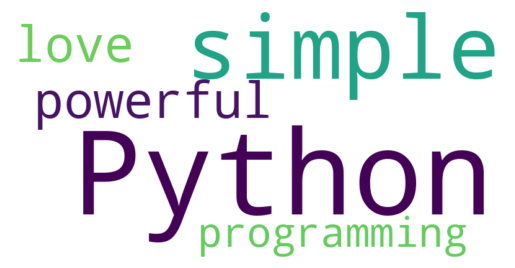

In [38]:
print("\n--- 8. Word cloud ---")
# A word cloud is a visual representation of text. Words that occur more frequently are usually displayed in larger fonts
try:
    from wordcloud import WordCloud
    import matplotlib.pyplot as plt

    cloud_text = "Python is simple and powerful. I love Python programming!"

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(cloud_text)

    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.show()

except ImportError:
    print("Install using: pip install wordcloud matplotlib")

In [39]:
print("\n--- 9. Machine learning, deep learning and neural networks ---")

# Machine learning allows a computer to learn patterns from examples.
# Deep learning is a type of machine learning that uses neural networks with multiple layers.

# A neuron multiplies inputs by weights, adds a bias, and normally
# passes the result through an activation function.
x = [2, 3, 1]
weights = [0.5, 0.2, 0.8]
bias = 0.1

weighted_sum = sum(
    value * weight for value, weight in zip(x, weights)
) + bias

print("Weighted sum + bias:", weighted_sum)
print("This result can be passed through an activation function.")


--- 9. Machine learning, deep learning and neural networks ---
Weighted sum + bias: 2.5000000000000004
This result can be passed through an activation function.


In [40]:
print("\n--- 10. Text generation: tokenizer ---")

# Text generation means producing new text.
# A simple next-word prediction model learns from a training paragraph and estimates which word should come next.

# Text generation learns to predict the next word in a sequence.
# Tokenizer assigns an integer ID to each word.
# Sections 10–15 are kept inside one try block so missing TensorFlow
# does not prevent the remaining concepts from being displayed.
try:
    import numpy as np
    import tensorflow as tf

    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Embedding, LSTM, Dense

    text = (
        "I love learning about machine learning and deep learning. "
        "Learning is fun and powerful. I love learning Python."
    )

    tokenizer = Tokenizer()
    tokenizer.fit_on_texts([text])

    print("Word index:", tokenizer.word_index)


    print("\n--- 11. Create input sequences ---")
    # Each growing sequence provides an example for predicting the next word.
    token_ids = tokenizer.texts_to_sequences([text])[0]

    sequences = []
    for i in range(2, len(token_ids) + 1):
        sequences.append(token_ids[:i])

    print("First few sequences:", sequences[:5])


    print("\n--- 12. Pad sequences ---")
    # Padding makes every sequence the same length.
    max_len = max(len(seq) for seq in sequences)

    padded = pad_sequences(
        sequences,
        maxlen=max_len,
        padding="pre"
    )

    print("Padded sequence array:\n", padded[:5])


    print("\n--- 13. Split X and y; one-hot encode y (PPT) ---")
    # X contains earlier words; y contains the next word to predict.
    # One-hot encoding represents the target word with a vector containing 1.
    sequences_array = np.array(padded)

    X = sequences_array[:, :-1]
    y_ids = sequences_array[:, -1]

    vocab_size = len(tokenizer.word_index) + 1

    y = tf.keras.utils.to_categorical(
        y_ids,
        num_classes=vocab_size
    )

    print("X shape:", X.shape)
    print("y shape after one-hot encoding:", y.shape)


    print("\n--- 14. Build and train an LSTM model ---")
    # Embedding learns word vectors.
    # LSTM learns sequence patterns.
    # Dense + softmax predicts the next word.
    model = Sequential([
        Embedding(vocab_size, 10),
        LSTM(32),
        Dense(vocab_size, activation="softmax")
    ])

    model.compile(
        loss="categorical_crossentropy",
        optimizer="adam",
        metrics=["accuracy"]
    )

    # A small number of epochs keeps the classroom demonstration manageable.
    model.fit(X, y, epochs=100, verbose=0)

    print("Model training complete.")


    print("\n--- 15. Generate new text ---")
    # Start with a seed phrase, predict a word, and append it repeatedly.
    def generate_text(seed_text, next_words=3):
        for _ in range(next_words):
            token_list = tokenizer.texts_to_sequences([seed_text])[0]

            # The input length must match the model's training input length.
            token_list = pad_sequences(
                [token_list],
                maxlen=X.shape[1],
                padding="pre"
            )

            predicted = model.predict(token_list, verbose=0)[0]
            predicted_id = int(np.argmax(predicted))
            predicted_word = tokenizer.index_word.get(predicted_id, "")

            if not predicted_word:
                break

            seed_text += " " + predicted_word

        return seed_text

    print("Generated text:", generate_text("machine", next_words=3))

except ImportError as error:
    print("\nTensorFlow or a required package is missing.")
    print("Install using: pip install tensorflow")
    print("Details:", error)


--- 10. Text generation: tokenizer ---
Word index: {'learning': 1, 'i': 2, 'love': 3, 'and': 4, 'about': 5, 'machine': 6, 'deep': 7, 'is': 8, 'fun': 9, 'powerful': 10, 'python': 11}

--- 11. Create input sequences ---
First few sequences: [[2, 3], [2, 3, 1], [2, 3, 1, 5], [2, 3, 1, 5, 6], [2, 3, 1, 5, 6, 1]]

--- 12. Pad sequences ---
Padded sequence array:
 [[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 3]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 3 1]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 3 1 5]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 2 3 1 5 6]
 [0 0 0 0 0 0 0 0 0 0 0 0 2 3 1 5 6 1]]

--- 13. Split X and y; one-hot encode y (PPT) ---
X shape: (17, 17)
y shape after one-hot encoding: (17, 12)

--- 14. Build and train an LSTM model ---


Model training complete.

--- 15. Generate new text ---


Generated text: machine learning learning learning
